In [9]:
from benchmarklib.pipeline import PipelineCompiler
from benchmarklib.pipeline.synthesis import XAGSynthesizer, QCFSynthesizer
from qiskit_ibm_transpiler import generate_ai_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit.transpiler import generate_preset_pass_manager
import qiskit
from typing import Tuple

from experiments import ExperimentProblem

In [2]:
service = QiskitRuntimeService()
backend = service.backend(name="ibm_rensselaer")

In [3]:
compiler_qcf = PipelineCompiler(
    synthesizer = QCFSynthesizer(),
    steps = [], 
    name="CLASSICAL_FUNCTION",
    backend = backend, 
    pass_manager_factory = generate_preset_pass_manager,
    transpile_options = {"optimization_level": 3}
)

compiler_xag = PipelineCompiler(
    synthesizer = XAGSynthesizer(),
    steps = [], 
    name="XAG",
    backend = backend, 
    pass_manager_factory = generate_preset_pass_manager,
    transpile_options = {"optimization_level": 3}
)

In [4]:
def target_fn(x: Tuple[bool]) -> bool:
    # majority of three
    return (x[0] and x[1]) or (x[1] and x[2]) or (x[0] and x[2])

target_fn_src = """
def verify(inpt: Tuple[bool]) -> bool:
    return (inpt[0] and inpt[1]) or (inpt[1] and inpt[2]) or (inpt[0] and inpt[2])
"""

problem = ExperimentProblem(
    name="majority_of_three",
    n=3
)
problem.verifier_src = target_fn_src

In [5]:
from qiskit.circuit.library import PhaseOracleGate
g = PhaseOracleGate("(x1 and x2) or (x2 and x3) or (x1 and x3)", var_order=["x1", "x2", "x3", "result"])

In [20]:
g.num_qubits

3

In [27]:
from qiskit import QuantumCircuit
import qiskit
circuit = QuantumCircuit(10)
circuit.append(g, [0, 1, 2])
circuit.decompose()
circuit = qiskit.transpile(circuit, backend=backend)
circuit.draw()

ValueError: Unknown node: <class 'ast.BoolOp'>

In [6]:
result = compiler_qcf.compile(problem)
oracle_qcf = result.synthesis_circuit


oracle_qcf.draw()

0
1
1
2
0
2


q_0: ──o────■───────
       │    │       
q_1: ──■────┼────■──
       │    │    │  
q_2: ──┼────■────o──
     ┌─┴─┐┌─┴─┐┌─┴─┐
q_3: ┤ X ├┤ X ├┤ X ├
     └───┘└───┘└───┘

In [7]:
result = compiler_xag.compile(problem)
oracle_xag = result.synthesis_circuit
oracle_xag.draw()

0
1
1
2
0
2


q_0: ───────■─────────■────────────
     ┌───┐  │         │  ┌───┐     
q_1: ┤ X ├──┼────■────┼──┤ X ├─────
     └─┬─┘┌─┴─┐  │  ┌─┴─┐└─┬─┘     
q_2: ──■──┤ X ├──■──┤ X ├──■────■──
          └───┘┌─┴─┐└───┘     ┌─┴─┐
q_3: ──────────┤ X ├──────────┤ X ├
               └───┘          └───┘

In [17]:
oracle_qcf_transpiled = qiskit.transpile(oracle_qcf, basis_gates=["x", "cx", "rz"])
oracle_qcf_transpiled.draw()

TranspilerError: 'Unable to translate the operations in the circuit: {("ccx", 3)} to the backend\'s (or manually specified) target basis: {"reset", "cx", "rz", "while_loop", "measure", "delay", "x", "switch_case", "box", "for_loop", "if_else", "barrier", "snapshot", "store"}. This likely means the target basis is not universal or there are additional equivalence rules needed in the EquivalenceLibrary being used. For more details on this error see: https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.transpiler.passes.BasisTranslator#translation-errors'

In [15]:
oracle_xag_transpiled = qiskit.transpile(oracle_xag, basis_gates=["x", "cx", "ccx"])
oracle_xag_transpiled.draw()

q_0: ───────■─────────■────────────
     ┌───┐  │         │  ┌───┐     
q_1: ┤ X ├──┼────■────┼──┤ X ├─────
     └─┬─┘┌─┴─┐  │  ┌─┴─┐└─┬─┘     
q_2: ──■──┤ X ├──■──┤ X ├──■────■──
          └───┘┌─┴─┐└───┘     ┌─┴─┐
q_3: ──────────┤ X ├──────────┤ X ├
               └───┘          └───┘

In [21]:
result.artifacts["nxag"]

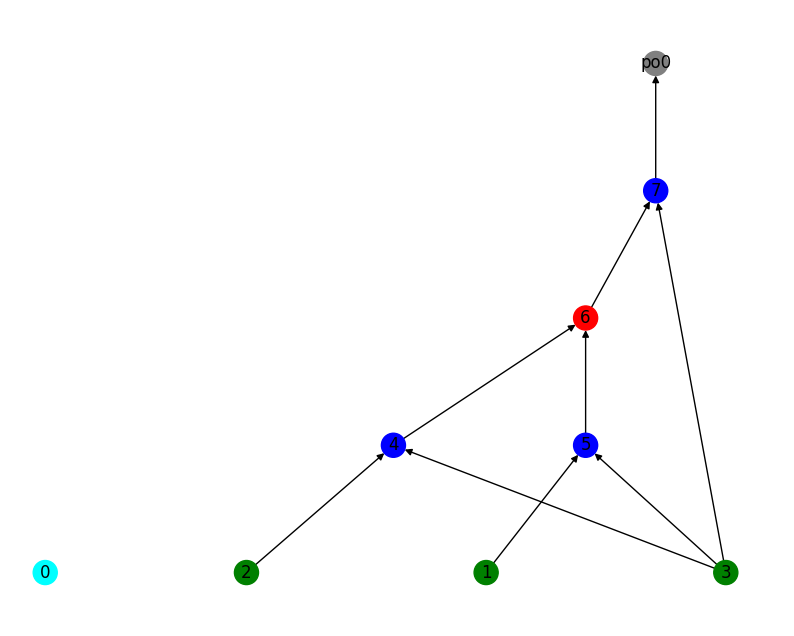

In [ ]:
import matplotlib.pyplot as plt
from xag_utils import PyXAG

fig, ax = plt.subplots(figsize=(10, 8))
PyXAG(result.artifacts["nxag"]).draw(ax=ax)